# Scrap notebooks

This notebook is just a compilation of scrapy tests to view functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sympy as sym

In [2]:
%matplotlib widget

In [3]:
phi = 0.3
phi_min = 0.1
phi_max = 0.9

phi_var = sym.symbols('varphi', positive=True) # phi is lower than 1 but no assumption system

alpha = 2
beta = 1
gamma = 4
delta = beta * gamma / (beta + gamma)

alpha_var, beta_var, gamma_var = sym.symbols('alpha beta gamma', positive=True)
delta_expr = beta_var * gamma_var / (beta_var + gamma_var)
delta_var = sym.symbols('delta', positive=True) # delta_var and delta_expr cannot be linked

f = 0.5
f_min = 0
f_max = 10

f_var = sym.symbols('f', nonnegative=True)

E = 0.3
E_min = 0
E_max = 10

E_var = sym.symbols('E', nonnegative=True)

N = 10000
N_min = 1
N_max = 100000

N_var = sym.symbols('N', positive=True)

s = 5000
s_min = 2000
s_max = 10000

s_var = sym.symbols('s', positive=True)

M = 3
M_min = 1
M_max = 8

M_var = sym.symbols('M', positive=True)

Delta_d = 1
#Delta_d = -2 * delta * N / (phi * s)
Delta_d_min = -5
Delta_d_max = 15

Delta_d_var = sym.symbols('Delta_d', real=True)

Delta_p = 3.2
#Delta_p = Delta_d + f + E + delta * N / (phi * s) # to delete
Delta_p_min = -5
Delta_p_max = 20

Delta_p_var = sym.symbols('Delta_p', real=True)

In [4]:
dim = 200

# first depending variables
N_ds = np.linspace(0, N, dim)
N_ps = np.linspace(0, N, dim)

N_d_var = sym.symbols('N_d', nonnegative=True)
N_p_var = sym.symbols('N_p', nonnegative=True)
N_s_expr = N_var - N_d_var - N_p_var
N_s_var = sym.symbols('N_s', nonnegative=True) # N_s_var and N_s_expr cannot be linked

N_ds, N_ps = np.meshgrid(N_ds, N_ps)
N_ss = N - N_ds - N_ps

mask = (N_ds >= 0) & (N_ps >= 0) & (N_ss >= 0) & (N_ps <= M * N_ds)

surface = np.zeros((dim, dim), dtype="float")

surface[~mask] = np.nan

Text(0.5, 0.5, 'N_p')

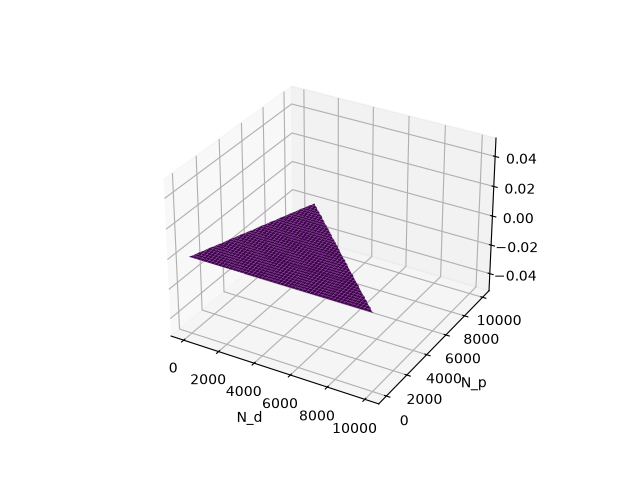

In [5]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.plot_surface(N_ds, N_ps, surface, cmap=plt.cm.viridis, linewidth=0.2)

ax.set_xlabel('N_d')
ax.set_ylabel('N_p')


In [6]:
SC = (delta / s) * ((N_ss)**2/(1-phi) + (N_ds**2 + N_ds * N_ps)/phi)\
    + (N_ss + N_ds) * (f + E) + N_ds * Delta_d + N_ps * Delta_p

SC_expr = (delta_var / s_var) * ((N_s_expr)**2/(1-phi_var) + (N_d_var**2 + N_d_var * N_p_var)/phi_var)\
    + (N_s_expr + N_d_var) * (f_var + E_var) + N_d_var * Delta_d_var + N_p_var * Delta_p_var

In [7]:
SC_expr

Delta_d*N_d + Delta_p*N_p + delta*((N - N_d - N_p)**2/(1 - varphi) + (N_d**2 + N_d*N_p)/varphi)/s + (E + f)*(N - N_p)

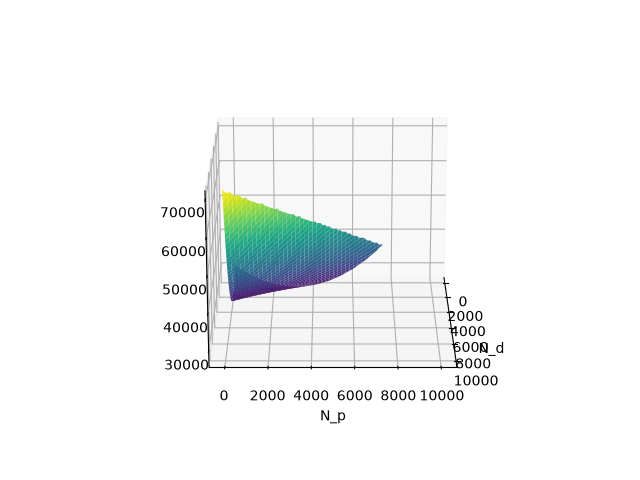

In [8]:
fig = plt.figure()
# some line of codes to see the saddle point

# N_ds = np.linspace(1821, 1822, dim)
# N_ps = np.linspace(803, 804, dim)
# N_ds, N_ps = np.meshgrid(N_ds, N_ps)
# N_ss = N - N_ds - N_ps
# SC = (delta / s) * ((N_ss)**2/(1-phi) + (N_ds**2 + N_ds * N_ps)/phi)\
#    + (N_ss + N_ds) * (f + E) + N_ds * Delta_d + N_ps * Delta_p
# 
# SC[(N_ds > 1821.3) & (N_ps > 1821.3- N_ds + 803.8)] = np.nan
# SC[(N_ds <1821.7) & (N_ps < 1821.7- N_ds + 803)] = np.nan
SC[~mask] = np.nan
ax = fig.add_subplot(projection='3d')
ax.plot_surface(N_ds, N_ps, SC, cmap=plt.cm.viridis, linewidth=0.2)
ax.set_xlabel('N_d')
ax.set_ylabel('N_p')
ax.view_init(20, 0, 0)

In [9]:
grad_SC = sym.Matrix([SC_expr.diff(var) for var in (N_d_var, N_p_var)])
grad_SC

Matrix([
[Delta_d + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s],
[  Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f]])

In [10]:
hessian_SC = sym.Matrix([[SC_expr.diff(var1).diff(var2) for var2 in (N_d_var, N_p_var)] for var1 in (N_d_var, N_p_var)])
hessian_SC

Matrix([
[delta*(2/(1 - varphi) + 2/varphi)/s, delta*(2/(1 - varphi) + 1/varphi)/s],
[delta*(2/(1 - varphi) + 1/varphi)/s,            2*delta/(s*(1 - varphi))]])

In [11]:
A = sym.symbols("A", positive=True)
H2 = hessian_SC.copy()
H2[1, 1] += A

In [12]:
H2

Matrix([
[delta*(2/(1 - varphi) + 2/varphi)/s, delta*(2/(1 - varphi) + 1/varphi)/s],
[delta*(2/(1 - varphi) + 1/varphi)/s,        A + 2*delta/(s*(1 - varphi))]])

In [13]:
lambd = sym.symbols("lambda", real=True)
pol = (H2 - lambd * sym.eye(2)).det()

In [14]:
pol2 = lambd ** 2 - lambd * (A + 2 * delta_var * (1 + phi_var) / (phi_var * (1 - phi_var) * s_var)) - (delta_var / (phi_var * s_var))**2 + 2 * delta_var / (phi_var * (1 - phi_var) * s_var) * A
pol2

2*A*delta/(s*varphi*(1 - varphi)) - delta**2/(s**2*varphi**2) + lambda**2 - lambda*(A + 2*delta*(varphi + 1)/(s*varphi*(1 - varphi)))

In [15]:
(pol - pol2).simplify()

0

In [16]:
a = 1
b = pol2.args[1].args[0] * pol2.args[1].args[2]
c = pol2.args[2] + pol2.args[3]

Delta_disc = b**2 - 4 * a* c
Delta_disc

-8*A*delta/(s*varphi*(1 - varphi)) + 4*delta**2/(s**2*varphi**2) + (-A - 2*delta*(varphi + 1)/(s*varphi*(1 - varphi)))**2

In [17]:
Delta_disc2 = A * A - 4 * delta_var / (s_var * phi_var) * A + 8 * delta_var**2 / (s_var**2 * phi_var**2) * ((1 + phi_var **2)/ (1 - phi_var)**2)
Delta_disc2

A**2 - 4*A*delta/(s*varphi) + 8*delta**2*(varphi**2 + 1)/(s**2*varphi**2*(1 - varphi)**2)

In [18]:
(Delta_disc2 - Delta_disc).simplify()

0

In [19]:
sol = -b - sym.sqrt(Delta_disc2)
print(sym.latex(sol))

A + \frac{2 \delta \left(\varphi + 1\right)}{s \varphi \left(1 - \varphi\right)} - \sqrt{A^{2} - \frac{4 A \delta}{s \varphi} + \frac{8 \delta^{2} \left(\varphi^{2} + 1\right)}{s^{2} \varphi^{2} \left(1 - \varphi\right)^{2}}}


In [20]:
hessian_SC_eigen = hessian_SC.eigenvals()
list(hessian_SC_eigen.keys())[0] # which is negative

-delta*(varphi + 1)/(s*varphi*(varphi - 1)) - sqrt(2)*delta*sqrt(varphi**2 + 1)/(s*varphi*(varphi - 1))

In [21]:
list(hessian_SC_eigen.keys())[1] # which is positive

-delta*(varphi + 1)/(s*varphi*(varphi - 1)) + sqrt(2)*delta*sqrt(varphi**2 + 1)/(s*varphi*(varphi - 1))

Text(0, 0.5, 'N_d')

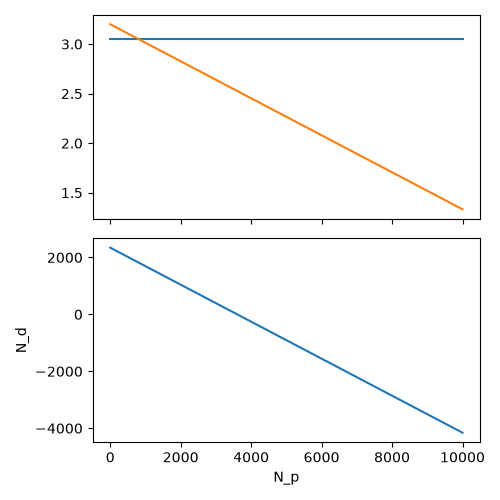

In [22]:
N_ps_1dim = N_ps[:, 0]
lhs = (f + E + delta * N / s + Delta_d * (1 + phi) / 2) * np.ones(dim)
rhs = delta * N_ps_1dim / ((1-phi) * s)  * (2 - 1/2 * (1+phi)*(1+phi) / phi) + Delta_p

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(5, 5), sharex=True, tight_layout=True)
ax1.plot(N_ps_1dim, lhs, label="lhs")
ax1.plot(N_ps_1dim, rhs, label="rhs")

N_ds_1dim_of_N_ps = - N_ps_1dim / 2 * (1+phi) + phi*(1-phi) * (N / (1-phi) - Delta_d * s / (2 * delta))
ax2.plot(N_ps_1dim, N_ds_1dim_of_N_ps, label="N_d")

ax2.set_xlabel('N_p')
ax2.set_ylabel('N_d')

In [23]:
hessian_SC_eigenvects = hessian_SC.eigenvects()
eigen_values = [hessian_SC_eigenvects[k][0] for k in range(len(hessian_SC_eigenvects)) for l in range (hessian_SC_eigenvects[k][1])]
eigen_vects = [hessian_SC_eigenvects[k][2] for k in range(len(hessian_SC_eigenvects))]

def list_of_vector_to_matrix(list_of_vect):
    matrix = list_of_vect[0]
    for k in range(1, len(list_of_vect)):
        matrix = matrix.row_join(list_of_vect[k])

    return matrix

eigen_vects = [list_of_vector_to_matrix(vect) for vect in eigen_vects]
eigen_vects = list_of_vector_to_matrix(eigen_vects)

diag_matrix = sym.Matrix.diag(*[eigen_values])
# eigen_vects_check, diag_check = hessian_SC.diagonalize()


#### just a few commands to understand basic linear algebra

In [24]:
# diag_matrix

In [25]:
# eigen_vects

In [26]:
# (eigen_vects.inv() * hessian_SC * eigen_vects).applyfunc(sym.cancel)

In [27]:
# diag_matrix.applyfunc(sym.cancel)

In [28]:
# eigen_vects_check, diag_check = hessian_SC.diagonalize()

In [29]:
# (eigen_vects_check.inv() * hessian_SC * eigen_vects_check).applyfunc(sym.cancel)

Ok, j’ai tout compris

Maintenant, on va trouver les solutions.

## Solving

Writing Lagrangian

In [30]:
# lamb = sym.symbols("lambda")
mu_s, mu_d, mu_p, mu_v = sym.symbols("mu_s mu_d mu_p mu_v", positive=True)

Lag_expr = SC_expr \
    - mu_s * N_s_expr \
    - mu_d * N_d_var \
    - mu_p * N_p_var \
    - mu_v * (M_var * N_d_var - N_p_var)
#     - lamb * (N_var - N_d_var - N_p_var - N_s_expr) \

In [31]:
Lag_expr

Delta_d*N_d + Delta_p*N_p - N_d*mu_d - N_p*mu_p + delta*((N - N_d - N_p)**2/(1 - varphi) + (N_d**2 + N_d*N_p)/varphi)/s - mu_s*(N - N_d - N_p) - mu_v*(M*N_d - N_p) + (E + f)*(N - N_p)

In [32]:
conditions = [Lag_expr.diff(var) for var in (N_d_var, N_p_var, mu_s, mu_d, mu_p, mu_v)]

In [33]:
conditions[0]

Delta_d - M*mu_v + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s - mu_d + mu_s

In [34]:
conditions[1]

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f - mu_p + mu_s + mu_v

In [35]:
conditions[2]

-N + N_d + N_p

In [36]:
conditions[3]

-N_d

In [37]:
conditions[4]

-N_p

In [38]:
conditions[5]

-M*N_d + N_p

In [39]:
SC_phi_1_expr = (delta_var / s_var) * ((N_d_var**2 + N_d_var * (N_var - N_d_var)))\
    + (N_d_var) * (f_var + E_var) + N_d_var * Delta_d_var + (N_var - N_d_var) * Delta_p_var

In [40]:
SC_phi_1_expr = SC_phi_1_expr.expand()

In [41]:
SC_phi_1_expr

Delta_d*N_d + Delta_p*N - Delta_p*N_d + E*N_d + N*N_d*delta/s + N_d*f

In [42]:
SC_phi_1_expr_diff = SC_phi_1_expr.diff(N_d_var)
SC_phi_1_expr_diff

Delta_d - Delta_p + E + N*delta/s + f

* Si c’est positif --> on va au min de $\Delta_d$, c’est-à-dire $N_d = \frac{N}{M+1}$.
* Si c’est négatif --> On va au max, c’est-à-dire $N_d = N$

### Maintenant on résoud pour $\varphi \in ]0, 1[$

In [43]:
SC_expr

Delta_d*N_d + Delta_p*N_p + delta*((N - N_d - N_p)**2/(1 - varphi) + (N_d**2 + N_d*N_p)/varphi)/s + (E + f)*(N - N_p)

In [44]:
conditions[0]

Delta_d - M*mu_v + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s - mu_d + mu_s

In [45]:
conditions[1]

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f - mu_p + mu_s + mu_v

Many cases

| $\mu_s >0$ and $N_d + N_p = N$ | $\mu_d > 0$ and $N_d = 0$ | $\mu_p > 0$ and $N_p = 0$ | $\mu_v > 0$ and $M N_d = N_p$ | Comment |
| ------------------------------ | ------------------------- | ------------------------- | ----------------------------- | ------- |
| False | False | False | False | Saddle point so not candidate for optimum &rarr; not explored.|
| False | False | False | True | **j/** We find $N_d = \frac{N \varphi}{M \varphi + 1} + \frac{s \left(M \left(- \varphi^{2} + \varphi\right) \left(- \Delta_{p} + E + f\right) + \Delta_d \left(\varphi^{2} - \varphi\right)\right)}{2 \delta \left(M + 1\right) \left(M \varphi + 1\right)}$, $N_p = MN_d$. To which we add the conditions $0 \leq N_d \leq \frac{N}{M+1}$ and $\frac{2 N \delta \left(M + 1\right)}{s} + \Delta_d \left(2 M \varphi + \varphi + 1\right) + \left(- \Delta_{p} + E + f\right) \left(M \varphi + M + 2\right) >0 $ |
| False | False | True | False | **i/**  We find $N_p = 0$ and $N_d = \varphi N \left( 1 - \left. \Delta_d \middle/ \frac{2\delta N}{(1-\varphi)s} \right. \right)$. Conditions $0 \leq N_d \leq N$ give $1 - 1/\varphi \leq \left. \Delta_d \middle/ \frac{2\delta N}{(1-\varphi)s} \right. \leq 1$. Additionnaly, we get $2\Delta_p > 2E + 2f + \Delta_d (1+\varphi) + \frac{2\delta N}{s}$. Here intuitions are harder to grasp… |
| False | False | True | True | **h/** We find $N_s = N$. Conditions are $M\Delta_p + \Delta_d > M(E + f) + (M+1)\frac{2\delta N}{(1-\varphi) s}$ and $\Delta_d > \frac{2\delta N}{(1-\varphi)s}$. Other conditions ($N_s \geq 0$ and $N_d \geq 0$) are satisfied. |
| False | True | False | False | **g/** Helped by the two additional conditions ($M N_d \geq N_p \geq 0$), we find $N_s = N$. Conditions are $\Delta_p = E + f + \frac{2\delta N}{(1-\varphi)s}$ and $\Delta_d > \frac{2\delta N}{(1-\varphi)s}$. (This implies $M\Delta_p + \Delta_d > M(E + f) + (M+1)\frac{2\delta N}{(1-\varphi) s}$)|
| False | True | False | True | **f/** We find $N_s = N$. Conditions are $M\Delta_p + \Delta_d + (M+1)\frac{2\delta N}{(1-\varphi) s}$ and $-\Delta_p + E + f + \frac{2\delta N}{(1-\varphi)s}$. (This implies $\Delta_d > \frac{2\delta N}{(1-\varphi)s}$.) Other condition ($N_s \geq 0$ and $N_p \geq 0$) are satisfied.|
| False | True | True | False | **e/** We find $N_s = N$. Conditions are $\Delta_d > \frac{2\delta N}{(1-\varphi)s}$ and $\Delta_p - E - f - \frac{2\delta N}{(1-\varphi)s}$. (This implies $M\Delta_p + \Delta_d > M(E + f) + (M+1)\frac{2\delta N}{(1-\varphi) s}$.) Other conditions ($N_s \geq 0$ and $MN_d \geq N_p$) are satisfied.|
| False | True | True | True | **d/** we find $N_s = N$, conditions are $\Delta_d > \frac{2\delta N}{(1-\varphi)s}$ and $M\Delta_p + \Delta_d > M(E + f) + (M+1)\frac{2\delta N}{(1-\varphi) s}$. Other condition ($N_s \geq 0$) is satisfied. (See code for more details cause it is parametric initially) |
| True | False | False | False | **c/** If $f + E + \Delta_d + \frac{\delta N}{\varphi s} = \Delta_p$, all mixes where $N_p = N - N_d$ is solution. Condition is  $\Delta_d + \frac{2\delta N}{\varphi s} < \frac{\delta N_p}{\varphi s}$. As long as other conditions ($N_d \geq 0$, $N_p \geq 0$, $M N_d \geq N_p$) are satisfied. If the equality is not satisfied, there is no solution. Due to equality conditions, Sympy finds no solution. |
| True | False | False | True | **b/** $N_s = 0$, $N_d = \frac{N}{M + 1}$, $N_p = \frac{M N}{M + 1}$. Conditions are $M(f+E) > M\Delta _p + \Delta_d + \frac{2\delta N}{\varphi s}$ and $E + f + \Delta_d + \frac{\delta N}{\varphi s} > \Delta _p$. Other conditions ($N_d \geq 0$ and $N_p \geq 0$) are satisfied. |
| True | False | True | False | **a/** $N_d = N$, $N_p = N_s = 0$. Conditions are $- \frac{2\delta N}{\varphi s} - \Delta_d > 0$ and $\Delta_{p} > E + \frac{\delta N}{\varphi s} + \Delta_d + f$. Other conditions ($N_d \geq 0$ and $M N_d \geq N_p$ are satisfied). |
| True | False | True | True | Impossible ($N_d = N$ and $MN_d = N_p = 0$) &rarr; not explored |
| True | True | False | False | Impossible ($N_p = N$ without drivers) &rarr; not explored |
| True | True | False | True | Impossible ($N = 0$) &rarr; not explored |
| True | True | True | False | Impossible ($N = 0$) &rarr; not explored |
| True | True | True | True | Impossible ($N = 0$) &rarr; not explored |

In [46]:
condition_N_d = conditions[0]
condition_N_p = conditions[1]
condition_mu_s = conditions[2]
condition_mu_d = conditions[3]
condition_mu_p = conditions[4]
condition_mu_v = conditions[5]

### Case a

In [47]:
condition0 = condition_N_d.subs({mu_d: 0, mu_v: 0})
condition1 = condition_N_p.subs({mu_d: 0, mu_v: 0})
condition2 = condition_mu_s.subs({mu_d: 0, mu_v: 0})
condition3 = condition_mu_p.subs({mu_d: 0, mu_v: 0})

In [48]:
condition0

Delta_d + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s + mu_s

In [49]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f - mu_p + mu_s

In [50]:
condition2

-N + N_d + N_p

In [51]:
condition3

-N_p

In [52]:
sols = sym.linsolve([condition0, condition1, condition2, condition3], (N_d_var, N_p_var, mu_s, mu_p))
sols_a = sols
sols_a

{(N, 0, (-Delta_d*s*varphi - 2*N*delta)/(s*varphi), (-Delta_d*s*varphi + Delta_p*s*varphi - E*s*varphi - N*delta - f*s*varphi)/(s*varphi))}

In [53]:
mu_s_sol = sols.args[0].args[2]
mu_p_sol = sols.args[0].args[3]
mu_s_sol = mu_s_sol.expand()
print(sym.latex(mu_s_sol))
mu_s_sol

- \Delta_{d} - \frac{2 N \delta}{s \varphi}


-Delta_d - 2*N*delta/(s*varphi)

In [54]:
mu_p_sol = mu_p_sol.expand()
print(sym.latex(mu_p_sol))
mu_p_sol

- \Delta_{d} + \Delta_{p} - E - \frac{N \delta}{s \varphi} - f


-Delta_d + Delta_p - E - N*delta/(s*varphi) - f

### Case b

In [55]:
condition0 = condition_N_d.subs({mu_d: 0, mu_p: 0})
condition1 = condition_N_p.subs({mu_d: 0, mu_p: 0})
condition2 = condition_mu_s.subs({mu_d: 0, mu_p: 0})
condition3 = condition_mu_v.subs({mu_d: 0, mu_p: 0})

In [56]:
condition0

Delta_d - M*mu_v + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s + mu_s

In [57]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f + mu_s + mu_v

In [58]:
condition2

-N + N_d + N_p

In [59]:
condition3

-M*N_d + N_p

In [60]:
sols = sym.linsolve([condition0, condition1, condition2, condition3], (N_d_var, N_p_var, mu_s, mu_v))
print(sym.latex(sols.args[0].args[0]))
print(sym.latex(sols.args[0].args[1]))
sols_b = sols
sols

\frac{N}{M + 1}
\frac{M N}{M + 1}


{(N/(M + 1), M*N/(M + 1), (-Delta_d*s*varphi - Delta_p*M*s*varphi + E*M*s*varphi + M*f*s*varphi - 2*N*delta)/(M*s*varphi + s*varphi), (Delta_d*s*varphi - Delta_p*s*varphi + E*s*varphi + N*delta + f*s*varphi)/(M*s*varphi + s*varphi))}

In [61]:
mu_s_sol = sols.args[0].args[2]
mu_v_sol = sols.args[0].args[3]
mu_s_sol = mu_s_sol.simplify()
print(sym.latex(mu_s_sol))
mu_s_sol

\frac{- \Delta_{d} s \varphi - \Delta_{p} M s \varphi + E M s \varphi + M f s \varphi - 2 N \delta}{s \varphi \left(M + 1\right)}


(-Delta_d*s*varphi - Delta_p*M*s*varphi + E*M*s*varphi + M*f*s*varphi - 2*N*delta)/(s*varphi*(M + 1))

In [62]:
mu_v_sol = mu_v_sol.simplify()
print(sym.latex(mu_v_sol))
mu_v_sol

\frac{\Delta_{d} s \varphi - \Delta_{p} s \varphi + E s \varphi + N \delta + f s \varphi}{s \varphi \left(M + 1\right)}


(Delta_d*s*varphi - Delta_p*s*varphi + E*s*varphi + N*delta + f*s*varphi)/(s*varphi*(M + 1))

### Case c

In [63]:
condition0 = condition_N_d.subs({mu_d: 0, mu_p: 0, mu_v: 0})
condition1 = condition_N_p.subs({mu_d: 0, mu_p: 0, mu_v: 0})
condition2 = condition_mu_s.subs({mu_d: 0, mu_p: 0, mu_v: 0})

In [64]:
condition0

Delta_d + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s + mu_s

In [65]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f + mu_s

In [66]:
condition2

-N + N_d + N_p

In [67]:
sols = sym.linsolve([condition0, condition1, condition2], (N_d_var, N_p_var, mu_s))
#print(sym.latex(sols.args[0].args[0]))
#print(sym.latex(sols.args[0].args[1]))
sols

EmptySet

### Case d

In [68]:
condition0 = condition_N_d.subs({mu_s: 0})
condition1 = condition_N_p.subs({mu_s: 0})
condition2 = condition_mu_d.subs({mu_s: 0})
condition3 = condition_mu_p.subs({mu_s: 0})
condition4 = condition_mu_v.subs({mu_s: 0})

In [69]:
condition0

Delta_d - M*mu_v + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s - mu_d

In [70]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f - mu_p + mu_v

In [71]:
condition2

-N_d

In [72]:
condition3

-N_p

In [73]:
condition4

-M*N_d + N_p

In [74]:
sols = sym.linsolve([condition0, condition1, condition2, condition3, condition4], (N_d_var, N_p_var, mu_d, mu_p, mu_v))
#print(sym.latex(sols.args[0].args[0]))
#print(sym.latex(sols.args[0].args[1]))
sols

{(0, 0, -M*mu_v + (Delta_d*s*varphi - Delta_d*s + 2*N*delta)/(s*varphi - s), mu_v + (Delta_p*s*varphi - Delta_p*s - E*s*varphi + E*s + 2*N*delta - f*s*varphi + f*s)/(s*varphi - s), mu_v)}

### Case e

In [75]:
condition0 = condition_N_d.subs({mu_s: 0, mu_v: 0})
condition1 = condition_N_p.subs({mu_s: 0, mu_v: 0})
condition2 = condition_mu_d.subs({mu_s: 0, mu_v: 0})
condition3 = condition_mu_p.subs({mu_s: 0, mu_v: 0})

In [76]:
condition0

Delta_d + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s - mu_d

In [77]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f - mu_p

In [78]:
condition2

-N_d

In [79]:
condition3

-N_p

In [80]:
sols = sym.linsolve([condition0, condition1, condition2, condition3], (N_d_var, N_p_var, mu_d, mu_p))
#print(sym.latex(sols.args[0].args[0]))
#print(sym.latex(sols.args[0].args[1]))
sols

{(0, 0, (Delta_d*s*varphi - Delta_d*s + 2*N*delta)/(s*varphi - s), (Delta_p*s*varphi - Delta_p*s - E*s*varphi + E*s + 2*N*delta - f*s*varphi + f*s)/(s*varphi - s))}

### Case f

In [81]:
condition0 = condition_N_d.subs({mu_s: 0, mu_p: 0})
condition1 = condition_N_p.subs({mu_s: 0, mu_p: 0})
condition2 = condition_mu_d.subs({mu_s: 0, mu_p: 0})
condition3 = condition_mu_v.subs({mu_s: 0, mu_p: 0})

In [82]:
condition0

Delta_d - M*mu_v + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s - mu_d

In [83]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f + mu_v

In [84]:
condition2

-N_d

In [85]:
condition3

-M*N_d + N_p

In [86]:
sols = sym.linsolve([condition0, condition1, condition2, condition3], (N_d_var, N_p_var, mu_d, mu_v))
#print(sym.latex(sols.args[0].args[0]))
#print(sym.latex(sols.args[0].args[1]))
sols

{(0, 0, (Delta_d*s*varphi - Delta_d*s + Delta_p*M*s*varphi - Delta_p*M*s - E*M*s*varphi + E*M*s + 2*M*N*delta - M*f*s*varphi + M*f*s + 2*N*delta)/(s*varphi - s), (-Delta_p*s*varphi + Delta_p*s + E*s*varphi - E*s - 2*N*delta + f*s*varphi - f*s)/(s*varphi - s))}

### Case g

In [87]:
condition0 = condition_N_d.subs({mu_s: 0, mu_p: 0, mu_v: 0})
condition1 = condition_N_p.subs({mu_s: 0, mu_p: 0, mu_v: 0})
condition2 = condition_mu_d.subs({mu_s: 0, mu_p: 0, mu_v: 0})

In [88]:
condition0

Delta_d + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s - mu_d

In [89]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f

In [90]:
condition2

-N_d

In [91]:
sols = sym.linsolve([condition0, condition1, condition2], (N_d_var, N_p_var, mu_d))
#print(sym.latex(sols.args[0].args[0]))
#print(sym.latex(sols.args[0].args[1]))
sols

{(0, (Delta_p*s*varphi - Delta_p*s - E*s*varphi + E*s + 2*N*delta - f*s*varphi + f*s)/(2*delta), (2*Delta_d*s*varphi - Delta_p*s*varphi - Delta_p*s + E*s*varphi + E*s + 2*N*delta + f*s*varphi + f*s)/(2*s*varphi))}

In [92]:
condition0.subs({N_d_var: sols.args[0].args[0], N_p_var: sols.args[0].args[1]})\
    .subs({Delta_p_var: E_var + f_var + 2 * delta_var * N_var / ((1-phi_var) * s_var)}).simplify()

(Delta_d*s*varphi - Delta_d*s + 2*N*delta - mu_d*s*varphi + mu_d*s)/(s*(varphi - 1))

In [93]:
condition0.subs({N_d_var: sols.args[0].args[0], N_p_var: sols.args[0].args[1]})\
    .subs({Delta_p_var: E_var + f_var + 2 * delta_var * N_var / ((1-phi_var) * s_var)}).simplify()

(Delta_d*s*varphi - Delta_d*s + 2*N*delta - mu_d*s*varphi + mu_d*s)/(s*(varphi - 1))

In [94]:
condition_N_d

Delta_d - M*mu_v + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s - mu_d + mu_s

In [95]:
condition_N_p

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f - mu_p + mu_s + mu_v

### Case h

In [96]:
condition0 = condition_N_d.subs({mu_s: 0, mu_d: 0})
condition1 = condition_N_p.subs({mu_s: 0, mu_d: 0})
condition2 = condition_mu_p.subs({mu_s: 0, mu_d: 0})
condition3 = condition_mu_v.subs({mu_s: 0, mu_d: 0})

In [97]:
condition0

Delta_d - M*mu_v + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s

In [98]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f - mu_p + mu_v

In [99]:
condition2

-N_p

In [100]:
condition3

-M*N_d + N_p

In [101]:
sols = sym.linsolve([condition0, condition1, condition2, condition3], (N_d_var, N_p_var, mu_p, mu_v))
#print(sym.latex(sols.args[0].args[0]))
#print(sym.latex(sols.args[0].args[1]))
sols

{(0, 0, (Delta_d*s*varphi - Delta_d*s + Delta_p*M*s*varphi - Delta_p*M*s - E*M*s*varphi + E*M*s + 2*M*N*delta - M*f*s*varphi + M*f*s + 2*N*delta)/(M*s*varphi - M*s), (Delta_d*s*varphi - Delta_d*s + 2*N*delta)/(M*s*varphi - M*s))}

### Case i

In [102]:
condition0 = condition_N_d.subs({mu_s: 0, mu_d: 0, mu_v: 0})
condition1 = condition_N_p.subs({mu_s: 0, mu_d: 0, mu_v: 0})
condition2 = condition_mu_p.subs({mu_s: 0, mu_d: 0, mu_v: 0})

In [103]:
condition0

Delta_d + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s

In [104]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f - mu_p

In [105]:
condition2

-N_p

In [106]:
sols = sym.linsolve([condition0, condition1, condition2], (N_d_var, N_p_var, mu_p))
#print(sym.latex(sols.args[0].args[0]))
#print(sym.latex(sols.args[0].args[1]))
sols_i = sols
sols

{((Delta_d*s*varphi**2 - Delta_d*s*varphi + 2*N*delta*varphi)/(2*delta), 0, (-Delta_d*s*varphi - Delta_d*s + 2*Delta_p*s - 2*E*s - 2*N*delta - 2*f*s)/(2*s))}

In [107]:
(phi_var * N_var * (1 - Delta_d_var / (2 * delta_var * N_var / ((1 - phi_var) * s_var)))).expand() - sols.args[0].args[0].expand()

0

### Case j

In [108]:
condition0 = condition_N_d.subs({mu_s: 0, mu_d: 0, mu_p: 0})
condition1 = condition_N_p.subs({mu_s: 0, mu_d: 0, mu_p: 0})
condition2 = condition_mu_v.subs({mu_s: 0, mu_d: 0, mu_p: 0})

In [109]:
condition0

Delta_d - M*mu_v + delta*((-2*N + 2*N_d + 2*N_p)/(1 - varphi) + (2*N_d + N_p)/varphi)/s

In [110]:
condition1

Delta_p - E + delta*(N_d/varphi + (-2*N + 2*N_d + 2*N_p)/(1 - varphi))/s - f + mu_v

In [111]:
condition2

-M*N_d + N_p

In [112]:
sols = sym.linsolve([condition0, condition1, condition2], (N_d_var, N_p_var, mu_v))
#print(sym.latex(sols.args[0].args[0]))
#print(sym.latex(sols.args[0].args[1]))
sols_j = sols
sols

{((Delta_d*s*varphi**2 - Delta_d*s*varphi + Delta_p*M*s*varphi**2 - Delta_p*M*s*varphi - E*M*s*varphi**2 + E*M*s*varphi + 2*M*N*delta*varphi - M*f*s*varphi**2 + M*f*s*varphi + 2*N*delta*varphi)/(2*M**2*delta*varphi + 2*M*delta*varphi + 2*M*delta + 2*delta), (Delta_d*M*s*varphi**2 - Delta_d*M*s*varphi + Delta_p*M**2*s*varphi**2 - Delta_p*M**2*s*varphi - E*M**2*s*varphi**2 + E*M**2*s*varphi + 2*M**2*N*delta*varphi - M**2*f*s*varphi**2 + M**2*f*s*varphi + 2*M*N*delta*varphi)/(2*M**2*delta*varphi + 2*M*delta*varphi + 2*M*delta + 2*delta), (2*Delta_d*M*s*varphi + Delta_d*s*varphi + Delta_d*s - Delta_p*M*s*varphi - Delta_p*M*s - 2*Delta_p*s + E*M*s*varphi + E*M*s + 2*E*s + 2*M*N*delta + M*f*s*varphi + M*f*s + 2*N*delta + 2*f*s)/(2*M**2*s*varphi + 2*M*s*varphi + 2*M*s + 2*s))}

In [113]:
num = sols.args[0].args[0].args[1]\
    .collect(Delta_p_var)\
    .collect(E_var)\
    .collect(f_var)\
    .collect(Delta_d_var)\
    .collect(2*delta_var * N_var * phi_var)\
    .collect(s_var)\
    .collect(-M_var * phi_var * phi_var + M_var * phi_var)\
    .collect(M_var)

num

2*N*delta*varphi*(M + 1) + s*(Delta_d*(varphi**2 - varphi) + M*(-varphi**2 + varphi)*(-Delta_p + E + f))

In [114]:
dem = sols.args[0].args[0].args[0].args[0]\
    .factor()

dem

2*delta*(M + 1)*(M*varphi + 1)

In [115]:
print(sym.latex(num.args[0] / dem + num.args[1] / dem))
num.args[0] / dem + num.args[1] / dem

\frac{N \varphi}{M \varphi + 1} + \frac{s \left(\Delta_{d} \left(\varphi^{2} - \varphi\right) + M \left(- \varphi^{2} + \varphi\right) \left(- \Delta_{p} + E + f\right)\right)}{2 \delta \left(M + 1\right) \left(M \varphi + 1\right)}


N*varphi/(M*varphi + 1) + s*(Delta_d*(varphi**2 - varphi) + M*(-varphi**2 + varphi)*(-Delta_p + E + f))/(2*delta*(M + 1)*(M*varphi + 1))

In [116]:
num.args[1] / dem

N*varphi/(M*varphi + 1)

In [117]:
num = sols.args[0].args[2].args[1]\
    .collect(E_var)\
    .collect(f_var)\
    .collect(Delta_d_var)\
    .collect(Delta_p_var)\
    .collect(M_var * s_var * phi_var + M_var * s_var + 2 * s_var)\
    .collect(2 * N_var * delta_var)\
    .collect(s_var)
    

num

2*N*delta*(M + 1) + s*(Delta_d*(2*M*varphi + varphi + 1) + (-Delta_p + E + f)*(M*varphi + M + 2))

In [118]:
dem = sols.args[0].args[2].args[0].args[0]\
    .factor()

dem

2*s*(M + 1)*(M*varphi + 1)

In [119]:
print(sym.latex(num.args[0] / s_var + num.args[1] / s_var))

num.args[0] / s_var + num.args[1] / s_var

\Delta_{d} \left(2 M \varphi + \varphi + 1\right) + \frac{2 N \delta \left(M + 1\right)}{s} + \left(- \Delta_{p} + E + f\right) \left(M \varphi + M + 2\right)


Delta_d*(2*M*varphi + varphi + 1) + 2*N*delta*(M + 1)/s + (-Delta_p + E + f)*(M*varphi + M + 2)

### Plotting solutions

In [120]:
SC_eval = sym.lambdify(
    (N_d_var, N_p_var, delta_var, s_var, M_var, f_var, E_var, phi_var, N_var, Delta_d_var, Delta_p_var),
    SC_expr,
    modules='numpy')

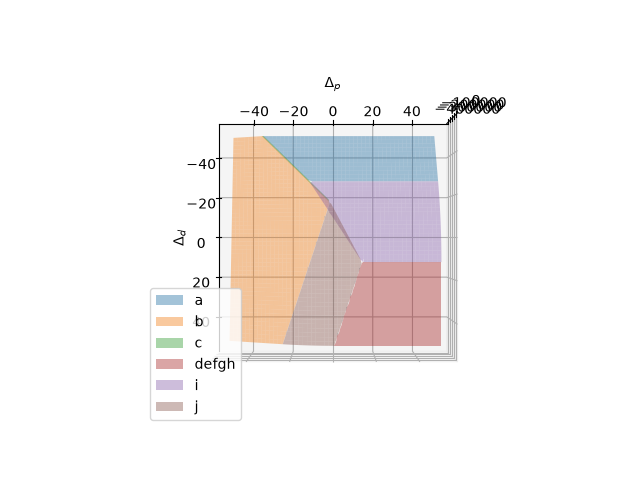

In [121]:
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.set_xlabel(r'$\Delta_d$')
ax.set_ylabel(r'$\Delta_p$')

N_value = 10000
s_value = 2000
alpha_value = 2
beta_value = 1
gamma_value = 4
delta_value = beta_value * gamma_value / (beta_value + gamma_value)
phi_value = 0.3
f_value = 1
E_value = 1
M_value = 3

#eps = 0.1
eps = 0.5
dim = 2000
alpha = 0.4

#Delta_d_value = np.linspace(-16.75, -16.25, dim)
#Delta_p_value = np.linspace(-1.3, -1.5, dim)

Delta_d_value = np.linspace(-50, 50, dim)
Delta_p_value = np.linspace(-50, 50, dim)

Delta_d_value, Delta_p_value = np.meshgrid(Delta_d_value, Delta_p_value)

N_d_a_value = np.full((dim, dim), N_value)
N_p_a_value = np.full((dim, dim), 0)
SC_a_value = SC_eval(
    N_d_a_value,
    N_p_a_value,
    delta_value,
    s_value,
    M_value,
    f_value,
    E_value,
    phi_value,
    N_value,
    Delta_d_value,
    Delta_p_value
)
#SC_a_value = np.zeros((dim, dim))
SC_a_value[-2*delta_value * N_value / (phi_value * s_value) - Delta_d_value <=0] = np.nan
SC_a_value[Delta_p_value - E_value - f_value - Delta_d_value - delta_value * N_value / (phi_value * s_value) <= 0] = np.nan
ax.plot_surface(Delta_d_value, Delta_p_value, SC_a_value, label="a", alpha=alpha)



N_d_b_value = np.full((dim, dim), N_value / (M_value + 1))
N_p_b_value = M_value * N_d_b_value
SC_b_value = SC_eval(
    N_d_b_value,
    N_p_b_value,
    delta_value,
    s_value,
    M_value,
    f_value,
    E_value,
    phi_value,
    N_value,
    Delta_d_value,
    Delta_p_value
)
#SC_b_value = np.zeros((dim, dim))
SC_b_value[M_value * (f_value + E_value - Delta_p_value) - Delta_d_value - 2 * delta_value * N_value / (phi_value * s_value) <= 0] = np.nan
SC_b_value[E_value + f_value + Delta_d_value + delta_value * N_value / (phi_value * s_value) - Delta_p_value <= 0] = np.nan
ax.plot_surface(Delta_d_value, Delta_p_value, SC_b_value, label="b", alpha=alpha)


N_d_c_value = np.full((dim, dim), N_value / (M_value + 1))
N_p_c_value = M * N_d_c_value
#N_d_c_value = np.full((dim, dim), N_value)
#N_p_c_value = np.full((dim, dim), 0)
SC_c_value = SC_eval(
    N_d_c_value,
    N_p_c_value,
    delta_value,
    s_value,
    M_value,
    f_value,
    E_value,
    phi_value,
    N_value,
    Delta_d_value,
    Delta_p_value
)
#SC_c_value = np.zeros((dim, dim))
SC_c_value[np.abs(f_value + E_value + Delta_d_value + delta_value * N_value / (phi_value * s_value) - Delta_p_value) > eps] = np.nan
SC_c_value[Delta_d_value + delta_value * (2 * N_value - N_p_c_value) / (phi_value * s_value) >= 0 ] = np.nan
ax.plot_surface(Delta_d_value, Delta_p_value, SC_c_value, label="c", alpha=alpha)

N_d_defgh_value = np.full((dim, dim), 0)
N_p_defgh_value = np.full((dim, dim), 0)
SC_defgh_value = SC_eval(
    N_d_defgh_value,
    N_p_defgh_value,
    delta_value,
    s_value,
    M_value,
    f_value,
    E_value,
    phi_value,
    N_value,
    Delta_d_value,
    Delta_p_value
)
#SC_defgh_value = np.zeros((dim, dim))
SC_defgh_value[M_value * (Delta_p_value - f_value - E_value) + Delta_d_value - (M_value + 1) * 2 * delta_value * N_value / ((1 - phi_value) * s_value) <= 0] = np.nan
SC_defgh_value[Delta_d_value - 2 * delta_value * N_value / ((1 - phi_value) * s_value) <= 0] = np.nan

ax.plot_surface(Delta_d_value, Delta_p_value, SC_defgh_value, label="defgh", alpha=alpha)


N_d_i_value = N_value * phi_value * (1 - Delta_d_value / (2 * delta_value * N_value / ((1 - phi_value) * s_value)))
N_p_i_value = np.full((dim, dim), 0)
SC_i_value = SC_eval(
    N_d_i_value,
    N_p_i_value,
    delta_value,
    s_value,
    M_value,
    f_value,
    E_value,
    phi_value,
    N_value,
    Delta_d_value,
    Delta_p_value
)
#SC_i_value = np.zeros((dim, dim))
SC_i_value[0 > N_d_i_value] = np.nan
SC_i_value[N_value < N_d_i_value] = np.nan
SC_i_value[2 * (Delta_p_value - E_value - f_value) - Delta_d_value * (1 + phi_value) - 2 * delta_value * N_value / s_value <= 0] = np.nan
ax.plot_surface(Delta_d_value, Delta_p_value, SC_i_value, label="i", alpha=alpha)

N_d_j_value = N_value * phi_value / (M_value * phi_value + 1) +\
    s_value*(M*phi_value * (1 - phi_value) * (-Delta_p_value + E_value + f_value) - Delta_d_value * phi_value * (1 - phi_value)) /\
    (2 * delta_value * (M_value + 1)*(M_value * phi_value + 1))
N_p_j_value = M_value * N_d_j_value
SC_j_value = SC_eval(
    N_d_j_value,
    N_p_j_value,
    delta_value,
    s_value,
    M_value,
    f_value,
    E_value,
    phi_value,
    N_value,
    Delta_d_value,
    Delta_p_value
)
#SC_j_value = np.zeros((dim, dim))
SC_j_value[N_d_j_value < 0] = np.nan # should be < but this is for testing
SC_j_value[N_d_j_value > N_value / (M_value + 1)] = np.nan
SC_j_value[2 * N_value * delta_value * (M_value + 1) / s_value + Delta_d_value * (2 * M_value * phi_value + phi_value + 1) + (-Delta_p_value + E_value + f_value) * (M_value * phi_value + M_value + 2) <= 0] = np.nan
ax.plot_surface(Delta_d_value, Delta_p_value, SC_j_value, label="j", alpha=alpha)

# just to check calculations about Delta_d and Delta_p

# Delta_d_dot_value = - (M_value + 2) / (M_value + 1) * delta_value * N_value / (phi_value * s_value)
# Delta_p_dot_value = 1/(M_value + 1) * (-delta_value * N_value / (phi_value * s_value) + (M+1) * (f_value + E_value))

#ax.scatter(Delta_d_dot_value, Delta_p_dot_value, 0)

ax.view_init(90, 0, 0)
ax.legend()

In [122]:
(M_value * phi_value + M_value + 2) / (2 * M_value * phi_value + phi_value + 1)

1.9032258064516132

In [123]:
2 / (1 + phi_value)

1.5384615384615383

In [124]:
SC_j_value.max(axis=0).max()

np.float64(nan)

In [125]:
sols_i

{((Delta_d*s*varphi**2 - Delta_d*s*varphi + 2*N*delta*varphi)/(2*delta), 0, (-Delta_d*s*varphi - Delta_d*s + 2*Delta_p*s - 2*E*s - 2*N*delta - 2*f*s)/(2*s))}

In [126]:
SC_expr.subs({N_d_var: sols_i.args[0].args[0], N_p_var: sols_i.args[0].args[1]}).simplify()

Delta_d**2*s*varphi**2/(4*delta) - Delta_d**2*s*varphi/(4*delta) + Delta_d*N*varphi + E*N + N**2*delta/s + N*f

In [127]:
SC_expr.subs({N_d_var: sols_i.args[0].args[0], N_p_var: sols_i.args[0].args[1]}).simplify().diff(phi_var)

Delta_d**2*s*varphi/(2*delta) - Delta_d**2*s/(4*delta) + Delta_d*N

In [128]:
sols_j

{((Delta_d*s*varphi**2 - Delta_d*s*varphi + Delta_p*M*s*varphi**2 - Delta_p*M*s*varphi - E*M*s*varphi**2 + E*M*s*varphi + 2*M*N*delta*varphi - M*f*s*varphi**2 + M*f*s*varphi + 2*N*delta*varphi)/(2*M**2*delta*varphi + 2*M*delta*varphi + 2*M*delta + 2*delta), (Delta_d*M*s*varphi**2 - Delta_d*M*s*varphi + Delta_p*M**2*s*varphi**2 - Delta_p*M**2*s*varphi - E*M**2*s*varphi**2 + E*M**2*s*varphi + 2*M**2*N*delta*varphi - M**2*f*s*varphi**2 + M**2*f*s*varphi + 2*M*N*delta*varphi)/(2*M**2*delta*varphi + 2*M*delta*varphi + 2*M*delta + 2*delta), (2*Delta_d*M*s*varphi + Delta_d*s*varphi + Delta_d*s - Delta_p*M*s*varphi - Delta_p*M*s - 2*Delta_p*s + E*M*s*varphi + E*M*s + 2*E*s + 2*M*N*delta + M*f*s*varphi + M*f*s + 2*N*delta + 2*f*s)/(2*M**2*s*varphi + 2*M*s*varphi + 2*M*s + 2*s))}

In [129]:
to_simplify = SC_expr.subs({N_d_var: sols_j.args[0].args[0], N_p_var: sols_j.args[0].args[1]}).simplify().diff(phi_var).simplify()
to_simplify.args

(1/delta,
 1/s,
 1/(M**3*varphi**2 + M**2*varphi**2 + 2*M**2*varphi + 2*M*varphi + M + 1),
 Delta_d**2*M*s**2*varphi**2/4 + Delta_d**2*s**2*varphi/2 - Delta_d**2*s**2/4 + Delta_d*Delta_p*M**2*s**2*varphi**2/2 + Delta_d*Delta_p*M*s**2*varphi - Delta_d*Delta_p*M*s**2/2 - Delta_d*E*M**2*s**2*varphi**2/2 - Delta_d*E*M*s**2*varphi + Delta_d*E*M*s**2/2 - Delta_d*M**2*f*s**2*varphi**2/2 + Delta_d*M*N*delta*s - Delta_d*M*f*s**2*varphi + Delta_d*M*f*s**2/2 + Delta_d*N*delta*s + Delta_p**2*M**3*s**2*varphi**2/4 + Delta_p**2*M**2*s**2*varphi/2 - Delta_p**2*M**2*s**2/4 - Delta_p*E*M**3*s**2*varphi**2/2 - Delta_p*E*M**2*s**2*varphi + Delta_p*E*M**2*s**2/2 - Delta_p*M**3*f*s**2*varphi**2/2 + Delta_p*M**2*N*delta*s - Delta_p*M**2*f*s**2*varphi + Delta_p*M**2*f*s**2/2 + Delta_p*M*N*delta*s + E**2*M**3*s**2*varphi**2/4 + E**2*M**2*s**2*varphi/2 - E**2*M**2*s**2/4 + E*M**3*f*s**2*varphi**2/2 - E*M**2*N*delta*s + E*M**2*f*s**2*varphi - E*M**2*f*s**2/2 - E*M*N*delta*s + M**3*f**2*s**2*varphi**2/4 - M**2*N

In [130]:
print(sym.latex(to_simplify.args[3].collect(phi_var))) # numerator to check that it is a polynome of varphi
to_simplify.args[3].collect(phi_var) # numerator

- \frac{\Delta_{d}^{2} s^{2}}{4} - \frac{\Delta_{d} \Delta_{p} M s^{2}}{2} + \frac{\Delta_{d} E M s^{2}}{2} + \Delta_{d} M N \delta s + \frac{\Delta_{d} M f s^{2}}{2} + \Delta_{d} N \delta s - \frac{\Delta_{p}^{2} M^{2} s^{2}}{4} + \frac{\Delta_{p} E M^{2} s^{2}}{2} + \Delta_{p} M^{2} N \delta s + \frac{\Delta_{p} M^{2} f s^{2}}{2} + \Delta_{p} M N \delta s - \frac{E^{2} M^{2} s^{2}}{4} - E M^{2} N \delta s - \frac{E M^{2} f s^{2}}{2} - E M N \delta s - M^{2} N^{2} \delta^{2} - M^{2} N \delta f s - \frac{M^{2} f^{2} s^{2}}{4} - M N^{2} \delta^{2} - M N \delta f s + \varphi^{2} \left(\frac{\Delta_{d}^{2} M s^{2}}{4} + \frac{\Delta_{d} \Delta_{p} M^{2} s^{2}}{2} - \frac{\Delta_{d} E M^{2} s^{2}}{2} - \frac{\Delta_{d} M^{2} f s^{2}}{2} + \frac{\Delta_{p}^{2} M^{3} s^{2}}{4} - \frac{\Delta_{p} E M^{3} s^{2}}{2} - \frac{\Delta_{p} M^{3} f s^{2}}{2} + \frac{E^{2} M^{3} s^{2}}{4} + \frac{E M^{3} f s^{2}}{2} + \frac{M^{3} f^{2} s^{2}}{4}\right) + \varphi \left(\frac{\Delta_{d}^{2} s^{2}}{2} + 

-Delta_d**2*s**2/4 - Delta_d*Delta_p*M*s**2/2 + Delta_d*E*M*s**2/2 + Delta_d*M*N*delta*s + Delta_d*M*f*s**2/2 + Delta_d*N*delta*s - Delta_p**2*M**2*s**2/4 + Delta_p*E*M**2*s**2/2 + Delta_p*M**2*N*delta*s + Delta_p*M**2*f*s**2/2 + Delta_p*M*N*delta*s - E**2*M**2*s**2/4 - E*M**2*N*delta*s - E*M**2*f*s**2/2 - E*M*N*delta*s - M**2*N**2*delta**2 - M**2*N*delta*f*s - M**2*f**2*s**2/4 - M*N**2*delta**2 - M*N*delta*f*s + varphi**2*(Delta_d**2*M*s**2/4 + Delta_d*Delta_p*M**2*s**2/2 - Delta_d*E*M**2*s**2/2 - Delta_d*M**2*f*s**2/2 + Delta_p**2*M**3*s**2/4 - Delta_p*E*M**3*s**2/2 - Delta_p*M**3*f*s**2/2 + E**2*M**3*s**2/4 + E*M**3*f*s**2/2 + M**3*f**2*s**2/4) + varphi*(Delta_d**2*s**2/2 + Delta_d*Delta_p*M*s**2 - Delta_d*E*M*s**2 - Delta_d*M*f*s**2 + Delta_p**2*M**2*s**2/2 - Delta_p*E*M**2*s**2 - Delta_p*M**2*f*s**2 + E**2*M**2*s**2/2 + E*M**2*f*s**2 + M**2*f**2*s**2/2)

In [131]:
lhs = to_simplify.args[3].collect(phi_var).collect(N_var)

In [132]:
A = Delta_d_var + M_var * (Delta_p_var - E_var - f_var)
rhs = phi_var **2 * s_var **2 * M_var * A**2 / 4 \
    + phi_var * s_var**2 * A**2 / 2 \
    -N_var **2 * delta_var **2 * M_var * (M_var + 1) \
    + delta_var * s_var * (M_var + 1) * N_var * A \
    - s_var**2 * A**2 / 4
rhs

-M*N**2*delta**2*(M + 1) + M*s**2*varphi**2*(Delta_d + M*(Delta_p - E - f))**2/4 + N*delta*s*(Delta_d + M*(Delta_p - E - f))*(M + 1) + s**2*varphi*(Delta_d + M*(Delta_p - E - f))**2/2 - s**2*(Delta_d + M*(Delta_p - E - f))**2/4

In [133]:
rhs.expand().collect(phi_var).collect(N_var) - lhs

0

In [134]:
sols_a

{(N, 0, (-Delta_d*s*varphi - 2*N*delta)/(s*varphi), (-Delta_d*s*varphi + Delta_p*s*varphi - E*s*varphi - N*delta - f*s*varphi)/(s*varphi))}

In [135]:
expr = SC_expr.subs({N_d_var: sols_b.args[0].args[0], N_p_var: sols_b.args[0].args[1]}).simplify()
print(sym.latex(expr))
expr

\frac{N \left(N \delta + s \varphi \left(\Delta_{d} + \Delta_{p} M + E + f\right)\right)}{s \varphi \left(M + 1\right)}


N*(N*delta + s*varphi*(Delta_d + Delta_p*M + E + f))/(s*varphi*(M + 1))

In [136]:
SC_expr.subs({N_d_var: sols_i.args[0].args[0], N_p_var: sols_i.args[0].args[1]}).simplify().diff(phi_var).simplify()

Delta_d*(2*Delta_d*s*varphi - Delta_d*s + 4*N*delta)/(4*delta)

Checking a calculation for N goes to 0